## Setup — Google Colab or JupyterLab
Run the next cell once, then execute the notebook **from top to bottom**. NumPy and Matplotlib are normally available in Colab; no Sionna RT installation is needed.

In [1]:
import sys
import importlib.util
import subprocess

if importlib.util.find_spec("sionna") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "sionna-rt"
    ])
    print("Sionna RT installed.")
else:
    print("Sionna is already installed.")

Sionna is already installed.



## Research Question 1 - Radio Propagation

**How do radio signals propagate through different paths in an urban environment?**

### **Objective**

Explore how radio signals travel between a transmitter (TX) and receivers (RX) in the **Munich scene** using **Sionna RT**.

We investigate five propagation mechanisms:

- **LOS:** Direct signal path without obstacles.
- **Specular Reflection:** Signal bounces off a surface.
- **Diffuse Reflection (Scattering):** Signal spreads in different directions.
- **Refraction:** Signal travels through a material and changes direction.
- **Diffraction:** Signal bends around building edges.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sionna.rt

from sionna.rt import (
    load_scene,
    scene,
    Transmitter,
    Receiver,
    PlanarArray,
    PathSolver
)

jitc_llvm_init(): LLVM API initialization failed ..


In [3]:
# Load the Munich scene
scene = load_scene(scene.munich)

# Set the frequency to 3.5 GHz
scene.frequency = 3.5e9

print("Munich scene loaded!")

Munich scene loaded!


In [4]:
# Configure the transmitter antenna
scene.tx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    pattern="iso",
    polarization="V"
)

# Configure the receiver antenna
scene.rx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    pattern="iso",
    polarization="V"
)

print("Antennas configured!")

Antennas configured!


In [5]:
# Create one transmitter
tx = Transmitter(
    name="tx",
    position=[8.5, 21, 27]
)

scene.add(tx)

# Create the first receiver (LOS)
rx1 = Receiver(
    name="rx1",
    position=[45, 90, 1.5]
)

scene.add(rx1)

# Create the second receiver (NLOS)
rx2 = Receiver(
    name="rx2",
    position=[85.9, 10, 1.5]
)
scene.add(rx2)

In [6]:
# Create the ray tracing solver
#PathSolver calculates the possible propagation paths between the transmitter and receivers.
solver = PathSolver()

# Enable all propagation mechanisms
paths = solver(
    scene=scene,
    max_depth=1,
    los=True,
    specular_reflection=True,
    diffuse_reflection=True,
    refraction=True,
    diffraction=True
)

print("Propagation paths calculated!")


Propagation paths calculated!


In [7]:
# Visualize the propagation paths in the Munich scene
scene.preview(paths=paths)


### **Write Your Answer — RQ1**

**Question:** Based on the Munich scene visualization, how can radio signals reach a receiver when the direct path is blocked by buildings?

**Your Answer:**

...



## **Research Question 2 — LOS vs NLOS Comparison**

### **How does a building obstruction affect received signal power?**

### **Objective**

Compare the **Received Signal Strength (RSS)** in LOS and NLOS conditions using the Munich scene.

We use one transmitter (TX) and two receivers:

- **RX1 (LOS):** The signal can travel directly from TX to RX1.
- **RX2 (NLOS):** Buildings block the direct signal path to RX2.

Both receivers are approximately **82 meters** from the transmitter, but they are placed at different locations.

By keeping the distances nearly equal, we can better observe how building obstructions affect received signal power.


In [8]:
# Calculate only the direct signal paths
direct_paths = solver(
    scene=scene,
    max_depth=0,
    los=True
)

# Get the channel coefficients
a_direct, _ = direct_paths.cir(out_type="numpy")

# Check LOS/NLOS conditions for both receivers
for i, name in enumerate(scene.receivers.keys()):

    # Check if a direct path exists
    has_los = np.any(np.abs(a_direct[i]) > 0)

    status = "LOS" if has_los else "NLOS"

    print(f"{name}: {status}")

rx1: LOS
rx2: NLOS


In [9]:
# Calculate propagation paths for RQ2
paths_rq2 = solver(
    scene=scene,
    max_depth=3, #Max depth is the maximum number of interactions a signal path can have with objects.
    los=True,
    specular_reflection=True,
    diffuse_reflection=True,
    refraction=True,
    diffraction=True
)

print("Propagation paths calculated!")

Propagation paths calculated!


In [10]:
# Set the transmitter power to 30 dBm
tx_power_dbm = 30

# Get the channel coefficients from CIR
# We only need the channel coefficients for RSS
a, _ = paths_rq2.cir(out_type="numpy")

# Store the RSS results
rss_results = []

# Calculate RSS for each receiver
for i, name in enumerate(scene.receivers.keys()):

    # Select all path coefficients for the current receiver
    coefficients = a[i, 0, 0, 0, :, 0]

    # Calculate the channel power ratio by summing path powers
    channel_power_ratio = np.sum(np.abs(coefficients)**2)

    # Calculate RSS in dBm using the transmitter power
    rss = tx_power_dbm + 10 * np.log10(channel_power_ratio) 
    
    # Display the RSS value
    rss_results.append(rss)

    print(f"{name}: RSS = {rss:.2f} dBm")

rx1: RSS = -51.00 dBm
rx2: RSS = -55.04 dBm


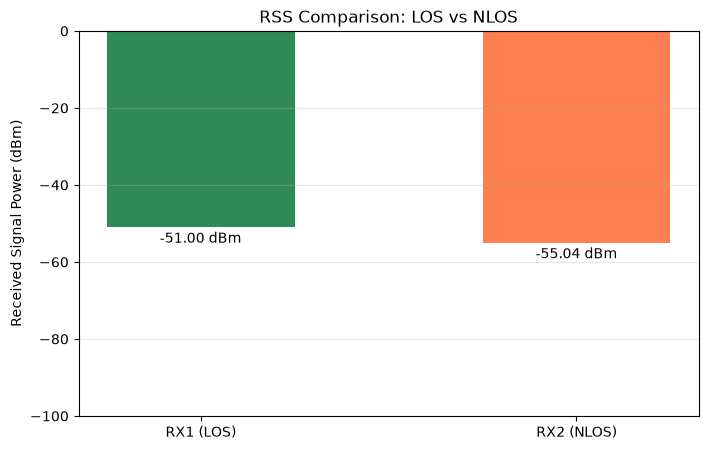

In [11]:
# Receiver names
receivers = ["RX1 (LOS)", "RX2 (NLOS)"]

# Create the RSS comparison graph
plt.figure(figsize=(8, 5))

plt.bar(
    receivers,
    rss_results,
    color=["seagreen", "coral"],
    width=0.5
)

# Add RSS values to the bars
for i, rss in enumerate(rss_results):
    if np.isfinite(rss):
        plt.text(i, rss - 4, f"{rss:.2f} dBm", ha="center")

# Add title and labels
plt.title("RSS Comparison: LOS vs NLOS")
plt.ylabel("Received Signal Power (dBm)")
plt.ylim(-100, 0)
plt.grid(axis="y", alpha=0.3)

plt.show()


### **Write Your Answer — RQ2**

**Question:** RX1 and RX2 are approximately the same distance from the transmitter. Why is the received signal power (RSS) different in LOS and NLOS conditions?

**Your Answer:**

...
